# V2 Poster Figures

Generates the 4 result figures for the AMR soft-prompting poster (Results section).
Pulls training metrics from wandb (`amr-soft-prompting` project) and computes the
conditioning-only naive-baseline numbers directly from CARD data.

Figures are saved as 300 DPI PNGs, sized to the poster's 8.5in x 6.4in figure
boxes exactly, to `outputs/poster_figures/` (also rendered inline below).


In [1]:
%matplotlib inline
import os
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import seaborn as sns
import wandb

sns.set_theme(style="white", font="sans-serif")
plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
})

# Reference palette (validated categorical + status/ink colors — see dataviz skill)
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
VIOLET = "#4a3aa7"
GREY = "#898781"     # muted/reference ink, not a categorical series
INK = "#0b0b0b"
INK2 = "#52514e"

FIG_DIR = "../../outputs/poster_figures"
os.makedirs(FIG_DIR, exist_ok=True)
DPI = 300
FIGSIZE = (8.5, 6.4)  # matches the poster's figure-box dimensions (width, height), in inches

api = wandb.Api()
PROJECT = "amr-soft-prompting"


wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/aidannguyen/.netrc.


## Figure 1 — Injection-mode ablation by task\n\nPulled live from wandb summary metrics \u2014 no hardcoded numbers. Metric key per task confirmed by inspection: `val/drug_class_subset_accuracy`, `val/resistance_mechanism_accuracy`, `val/amr_gene_family_accuracy`.

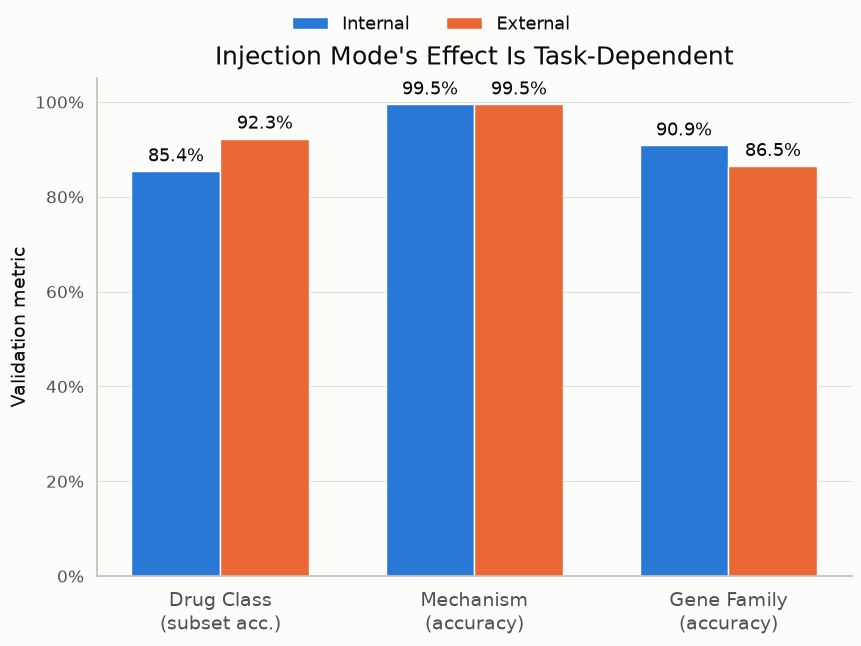

In [2]:
tasks = ["Drug Class\n(subset acc.)", "Mechanism\n(accuracy)", "Gene Family\n(accuracy)"]

internal_runs = ["mlvam3jw", "xpyy4zde", "x7f7gvh3"]
external_runs = ["p9f8pdmn", "oe13u15r", "p4kl9z5r"]
metric_keys_ablation = [
    "val/drug_class_subset_accuracy",
    "val/resistance_mechanism_accuracy",
    "val/amr_gene_family_accuracy",
]

internal_vals = [api.run(f"{PROJECT}/{rid}").summary[k] for rid, k in zip(internal_runs, metric_keys_ablation)]
external_vals = [api.run(f"{PROJECT}/{rid}").summary[k] for rid, k in zip(external_runs, metric_keys_ablation)]

x = np.arange(len(tasks))
width = 0.35

fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
b1 = ax.bar(x - width/2, internal_vals, width, label="Internal", color=BLUE)
b2 = ax.bar(x + width/2, external_vals, width, label="External", color=ORANGE)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h*100:.1f}%", (bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=13, color=INK)

ax.set_xticks(x)
ax.set_xticklabels(tasks, fontsize=14)
ax.set_ylabel("Validation metric", fontsize=14)
ax.tick_params(axis="y", labelsize=12)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("Injection Mode's Effect Is Task-Dependent", fontsize=18, pad=10)
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
fig.savefig(f"{FIG_DIR}/fig1_injection_mode_ablation.png", dpi=DPI)
plt.show()


## Figure 2 — Convergence speed as a signal-strength signature\n\nPulled live from wandb history, all 4 runs across both tasks and both injection modes: `xpyy4zde` (mechanism, internal), `oe13u15r` (mechanism, external), `x7f7gvh3` (gene family <- TA-proximity, internal), `p4kl9z5r` (gene family <- TA-proximity, external).

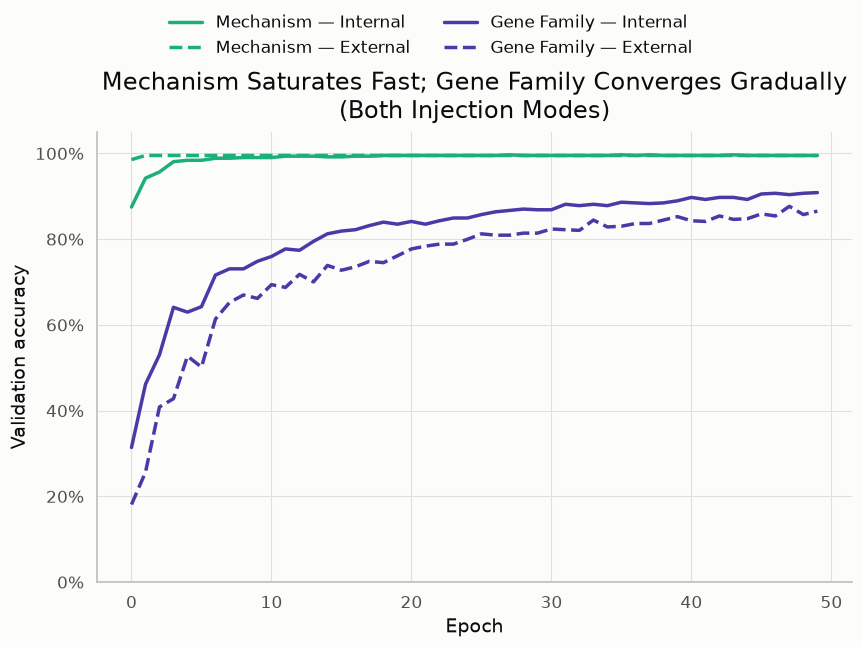

In [3]:
run_ids = {
    "Mechanism": {"internal": "xpyy4zde", "external": "oe13u15r"},
    "Gene Family": {"internal": "x7f7gvh3", "external": "p4kl9z5r"},
}
metric_keys = {
    "Mechanism": "val/resistance_mechanism_accuracy",
    "Gene Family": "val/amr_gene_family_accuracy",
}
task_colors = {"Mechanism": AQUA, "Gene Family": VIOLET}
mode_styles = {"internal": "-", "external": "--"}

histories = {}
for task, modes in run_ids.items():
    for mode, run_id in modes.items():
        run = api.run(f"{PROJECT}/{run_id}")
        hist = run.history(keys=["epoch", metric_keys[task]], pandas=True)
        histories[(task, mode)] = hist

fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
for (task, mode), hist in histories.items():
    ax.plot(hist["epoch"], hist[metric_keys[task]],
            color=task_colors[task], linestyle=mode_styles[mode], linewidth=2.5,
            label=f"{task} \u2014 {mode.capitalize()}")

ax.set_xlabel("Epoch", fontsize=14)
ax.set_ylabel("Validation accuracy", fontsize=14)
ax.tick_params(labelsize=12)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("Mechanism Saturates Fast; Gene Family Converges Gradually\n(Both Injection Modes)", fontsize=17, pad=10)
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, fontsize=12)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(f"{FIG_DIR}/fig2_convergence_signal_strength.png", dpi=DPI)
plt.show()


## Figure 3 — Trained model vs. conditioning-only naive baseline\n\nNaive baseline = majority-vote lookup table on the conditioning field alone (no ESM-2, no model). **Derivation below, live against the real split and real data** \u2014 no hardcoded numbers.

In [4]:
import os
import sys
import pickle
from collections import Counter, defaultdict

sys.path.insert(0, os.path.abspath("../.."))
from src.data.card_parser import load_card_dataset

REPO_ROOT = os.path.abspath("../..")
CARD_FASTA = f"{REPO_ROOT}/data/raw/protein_fasta_protein_homolog_model.fasta"
ARO_INDEX = f"{REPO_ROOT}/data/raw/aro_index.tsv"
TA_PROXIMITY = f"{REPO_ROOT}/data/processed/ta_proximity_results.json"
# Reuse the ACTUAL split artifact the real training runs were evaluated against
# (src/data/dataset.py's split_dataset, seed=42, stratified by mechanism, split
# on ARO accession) -- not a re-derived split, so the val set here is byte-identical
# to the one behind every val/* metric pulled from wandb elsewhere in this notebook.
with open(f"{REPO_ROOT}/outputs/internal/card_splits.pkl", "rb") as f:
    split_data = pickle.load(f)
train_accessions = {r.aro_accession for r in split_data["splits"]["train"]}
val_accessions = {r.aro_accession for r in split_data["splits"]["val"]}


def majority_lookup_eval(train_records, val_records, key_fn, target_fn):
    """Fit a majority-vote lookup table on train, score exact-match accuracy on val."""
    votes = defaultdict(Counter)
    global_votes = Counter()
    for r in train_records:
        votes[key_fn(r)][target_fn(r)] += 1
        global_votes[target_fn(r)] += 1
    global_majority = global_votes.most_common(1)[0][0]  # fallback for a val-only key
    lookup = {k: c.most_common(1)[0][0] for k, c in votes.items()}
    correct = sum(
        lookup.get(key_fn(r), global_majority) == target_fn(r) for r in val_records
    )
    return correct / len(val_records)


# Tasks 1 & 2: conditioning field is amr_gene_family, no TA-proximity join needed
records_12 = load_card_dataset(CARD_FASTA, ARO_INDEX)
train_12 = [r for r in records_12 if r.aro_accession in train_accessions]
val_12 = [r for r in records_12 if r.aro_accession in val_accessions]

# Task 1: drug_class <- gene_family. Multi-label, so the lookup table's "vote" is the
# exact label SET (sorted tuple) -- matching val/drug_class_subset_accuracy's exact-match semantics.
naive_drug_class = majority_lookup_eval(
    train_12, val_12,
    key_fn=lambda r: r.amr_gene_family,
    target_fn=lambda r: tuple(sorted(r.drug_classes)),
)

# Task 2: resistance_mechanism <- gene_family. Single-label, plain accuracy.
naive_mechanism = majority_lookup_eval(
    train_12, val_12,
    key_fn=lambda r: r.amr_gene_family,
    target_fn=lambda r: r.resistance_mechanism,
)

# Task 3: amr_gene_family <- ta_proximity_category. Needs the TA-proximity join.
records_3 = load_card_dataset(CARD_FASTA, ARO_INDEX, ta_proximity_path=TA_PROXIMITY)
train_3 = [r for r in records_3 if r.aro_accession in train_accessions]
val_3 = [r for r in records_3 if r.aro_accession in val_accessions]

naive_gene_family = majority_lookup_eval(
    train_3, val_3,
    key_fn=lambda r: r.ta_proximity_category,
    target_fn=lambda r: r.amr_gene_family,
)

# Trained model numbers, pulled live from the same wandb runs used elsewhere in this
# notebook -- the exact metric keys wandb logs for each task (confirmed by inspection).
trained_drug_class = api.run(f"{PROJECT}/p9f8pdmn").summary["val/drug_class_subset_accuracy"]
trained_mechanism = api.run(f"{PROJECT}/xpyy4zde").summary["val/resistance_mechanism_accuracy"]
trained_gene_family = api.run(f"{PROJECT}/x7f7gvh3").summary["val/amr_gene_family_accuracy"]

print(f"{'Task':<32}{'Trained':>10}{'Naive baseline':>16}")
print(f"{'Drug Class (subset acc.)':<32}{trained_drug_class:>10.4f}{naive_drug_class:>16.4f}")
print(f"{'Mechanism':<32}{trained_mechanism:>10.4f}{naive_mechanism:>16.4f}")
print(f"{'Gene Family (<- TA-proximity)':<32}{trained_gene_family:>10.4f}{naive_gene_family:>16.4f}")


Task                               Trained  Naive baseline
Drug Class (subset acc.)            0.9231          0.9201
Mechanism                           0.9952          0.9950
Gene Family (<- TA-proximity)       0.9087          0.1880


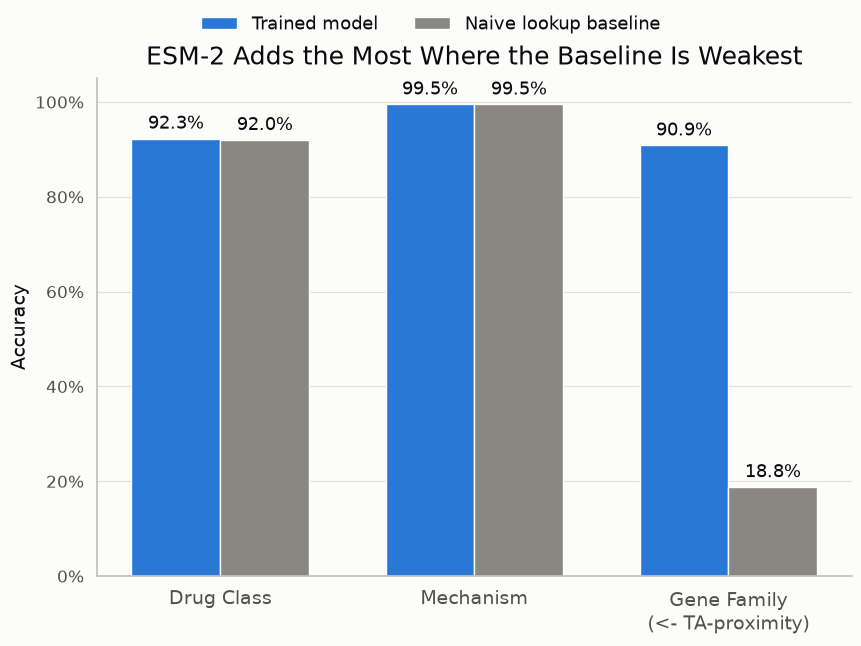

In [5]:
tasks3 = ["Drug Class", "Mechanism", "Gene Family\n(<- TA-proximity)"]
trained = [trained_drug_class, trained_mechanism, trained_gene_family]
naive_baseline = [naive_drug_class, naive_mechanism, naive_gene_family]

x = np.arange(len(tasks3))
width = 0.35

fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
b1 = ax.bar(x - width/2, trained, width, label="Trained model", color=BLUE)
b2 = ax.bar(x + width/2, naive_baseline, width, label="Naive lookup baseline", color=GREY)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h*100:.1f}%", (bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=13, color=INK)

ax.set_xticks(x)
ax.set_xticklabels(tasks3, fontsize=14)
ax.set_ylabel("Accuracy", fontsize=14)
ax.tick_params(axis="y", labelsize=12)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("ESM-2 Adds the Most Where the Baseline Is Weakest", fontsize=18, pad=10)
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=2, frameon=False, fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", visible=False)
fig.savefig(f"{FIG_DIR}/fig3_model_vs_naive_baseline.png", dpi=DPI)
plt.show()


## Figure 4 — Why Run 3's conditioning signal is deliberately weak\n\nTA-proximity category composition (n=6052 queryable ARO accessions).

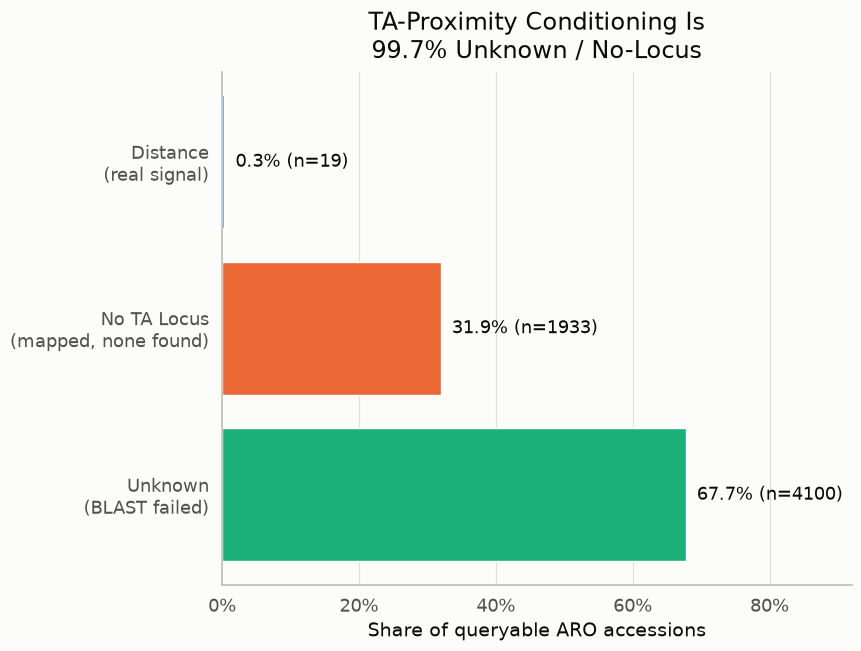

In [6]:
categories = ["Distance\n(real signal)", "No TA Locus\n(mapped, none found)", "Unknown\n(BLAST failed)"]
counts = [19, 1933, 4100]
total = sum(counts)
fracs = [c / total for c in counts]
colors = [BLUE, ORANGE, AQUA]

fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
bars = ax.barh(categories, fracs, color=colors)
for bar, c, f in zip(bars, counts, fracs):
    ax.annotate(f"{f*100:.1f}% (n={c})", (bar.get_width(), bar.get_y() + bar.get_height()/2),
                xytext=(8, 0), textcoords="offset points", ha="left", va="center",
                fontsize=13, color=INK)

ax.set_xlabel("Share of queryable ARO accessions", fontsize=14)
ax.tick_params(labelsize=13)
ax.set_xlim(0, 0.92)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("TA-Proximity Conditioning Is\n99.7% Unknown / No-Locus", fontsize=17, pad=10)
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG_DIR}/fig4_ta_proximity_composition.png", dpi=DPI)
plt.show()


## Figure 5 — Label leakage confound (V1, pre-fix)\n\n"Other interesting points" box. Landscape, sized to 9in x 6.75in (fits the box; no paragraph text baked in — that goes in a separate text box in the poster layout).\n\n**Draft paragraph (2 sentences):** *Our V1 architecture conditioned the resistance-mechanism and drug-class heads on their own ground-truth labels, letting them shortcut instead of learning from ESM-2. The result was near-ceiling accuracy from epoch 0, before any real training \u2014 fixed by switching to single-head models where the conditioning input and prediction target are never the same field.*\n\nTwo-panel design (inspired by an earlier diagnostic script): both V1 pre-fix runs \u2014 `zz67qllg` (internal) and `snm1i141` (external) \u2014 side by side per confounded metric. The point: injection mode doesn't matter here, because the head isn't learning from ESM-2 at all, it's just decoding its own conditioning input. External mechanism accuracy is a flat 100% from epoch 0.

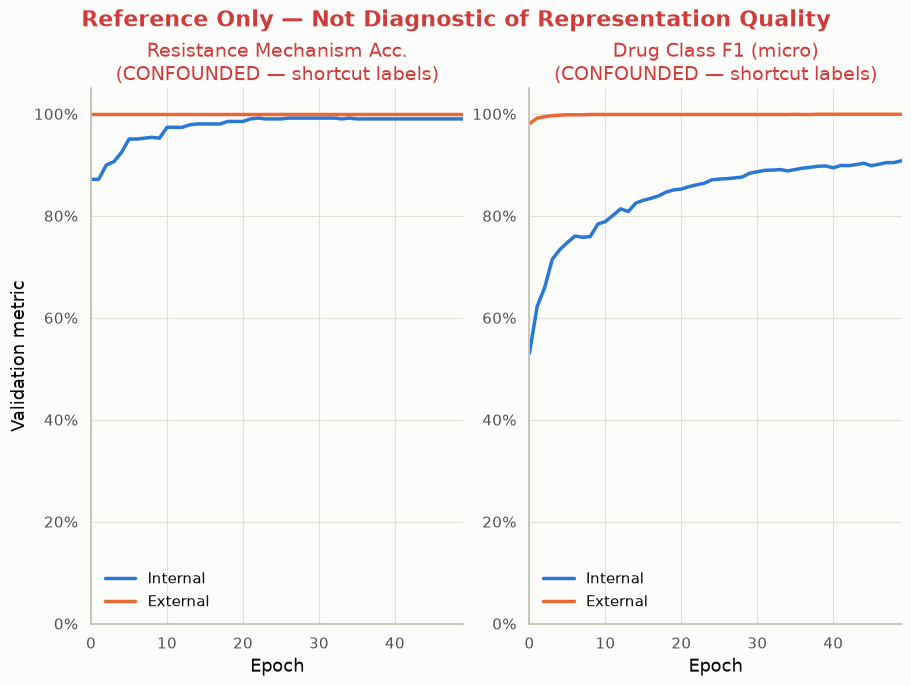

In [7]:
FIGSIZE_WIDE = (9, 6.75)  # landscape — same box, dimensions swapped so it's wider than tall

run_int = api.run(f"{PROJECT}/zz67qllg")  # V1 pre-fix, internal injection
run_ext = api.run(f"{PROJECT}/snm1i141")  # V1 pre-fix, external injection
keys = ["epoch", "val/resistance_mechanism_accuracy", "val/drug_class_f1_micro"]
hist_int = run_int.history(keys=keys, pandas=True)
hist_ext = run_ext.history(keys=keys, pandas=True)

CRITICAL = "#d03b3b"  # status-critical red, reserved for flagging the confound itself

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE, constrained_layout=True)

axes[0].plot(hist_int["epoch"], hist_int["val/resistance_mechanism_accuracy"],
             color=BLUE, linewidth=2.5, label="Internal")
axes[0].plot(hist_ext["epoch"], hist_ext["val/resistance_mechanism_accuracy"],
             color=ORANGE, linewidth=2.5, label="External")
axes[0].set_title("Resistance Mechanism Acc.\n(CONFOUNDED \u2014 shortcut labels)", fontsize=14, color=CRITICAL)

axes[1].plot(hist_int["epoch"], hist_int["val/drug_class_f1_micro"],
             color=BLUE, linewidth=2.5, label="Internal")
axes[1].plot(hist_ext["epoch"], hist_ext["val/drug_class_f1_micro"],
             color=ORANGE, linewidth=2.5, label="External")
axes[1].set_title("Drug Class F1 (micro)\n(CONFOUNDED \u2014 shortcut labels)", fontsize=14, color=CRITICAL)

for ax in axes:
    ax.set_xlabel("Epoch", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_ylim(0, 1.05)
    ax.set_xlim(0, 49)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.legend(fontsize=11, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Validation metric", fontsize=13)

fig.suptitle("Reference Only \u2014 Not Diagnostic of Representation Quality", fontsize=16, color=CRITICAL, fontweight="bold")
fig.savefig(f"{FIG_DIR}/fig5_label_leakage_confound.png", dpi=DPI)
plt.show()


## Figure 6 — Pipeline flow diagram, both injection modes stacked\n\nOne banner, sized to 22.01in x 6.59in, with internal (top) and external (bottom) stacked in the same image. Both share an identical box skeleton (Amino Acid Sequences -> ESM-2 -> Mean-Pooled Embeddings -> Combined Representation -> Classifier -> Prediction) so they line up \u2014 the only differences are (1) where the Conditioning Input -> Soft Prompt Module branch merges into the spine, and (2) whether Combined Representation is a real concatenation or a pass-through, exactly matching `src/models/esm2_wrapper.py`: internal *prepends* soft prompt tokens before the transformer encoder (so Combined Representation is just the pooled output, no separate merge op); external runs ESM-2 alone, then *concatenates* the flattened soft prompt with the mean-pooled output afterward.

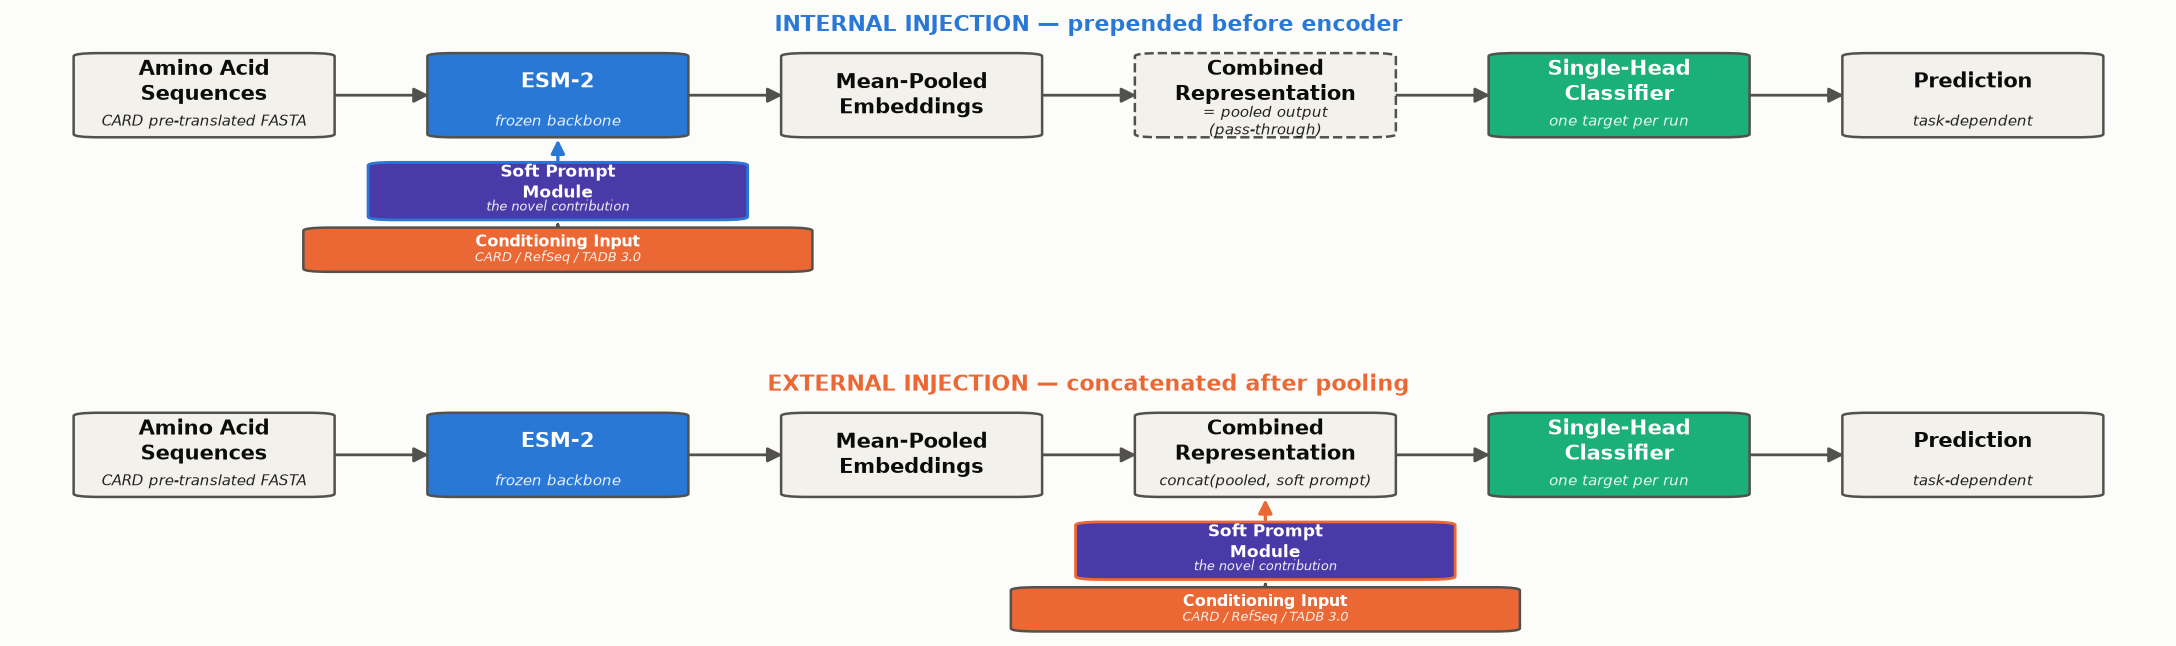

In [8]:
from matplotlib.patches import FancyBboxPatch

FIGSIZE_STACKED = (22.01, 6.59)
NEUTRAL_FILL = "#f2f1ec"


def draw_pipeline(ax, mode: str) -> None:
    """Draw one mode's pipeline (mode is 'internal' or 'external') onto the given axis."""
    accent = BLUE if mode == "internal" else ORANGE
    merge_idx = 1 if mode == "internal" else 3  # ESM-2 for internal, Combined Rep for external

    stages = [
        ("Amino Acid\nSequences", "CARD pre-translated FASTA", NEUTRAL_FILL, INK, False),
        ("ESM-2", "frozen backbone", BLUE, "white", False),
        ("Mean-Pooled\nEmbeddings", "", NEUTRAL_FILL, INK, False),
        ("Combined\nRepresentation",
         "= pooled output\n(pass-through)" if mode == "internal" else "concat(pooled, soft prompt)",
         NEUTRAL_FILL, INK, mode == "internal"),
        ("Single-Head\nClassifier", "one target per run", AQUA, "white", False),
        ("Prediction", "task-dependent", NEUTRAL_FILL, INK, False),
    ]

    n = len(stages)
    box_w, box_h = 0.105, 0.30
    y_main = 0.68
    centers = np.linspace(0.09, 0.91, n)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    boxes = []
    for (label, sub, fill, textcolor, dashed), cx in zip(stages, centers):
        box = FancyBboxPatch((cx - box_w/2, y_main - box_h/2), box_w, box_h,
                              boxstyle="round,pad=0.008,rounding_size=0.012",
                              linewidth=1.8, edgecolor=INK2, facecolor=fill, zorder=3,
                              linestyle="dashed" if dashed else "solid")
        ax.add_patch(box)
        boxes.append((cx, y_main))
        ax.text(cx, y_main + (0.05 if sub else 0), label, ha="center", va="center",
                fontsize=15, fontweight="bold", color=textcolor, zorder=4)
        if sub:
            ax.text(cx, y_main - 0.10, sub, ha="center", va="center",
                    fontsize=10.5, style="italic", color=textcolor, alpha=0.9, zorder=4)

    for (cx1, cy1), (cx2, cy2) in zip(boxes[:-1], boxes[1:]):
        ax.annotate("", xy=(cx2 - box_w/2 - 0.006, cy2), xytext=(cx1 + box_w/2 + 0.006, cy1),
                    arrowprops=dict(arrowstyle="-|>", color=INK2, lw=2, mutation_scale=22), zorder=2)

    # Soft Prompt Module, directly under whichever box this mode merges into
    merge_cx = centers[merge_idx]
    sp_cx, sp_cy = merge_cx, 0.32
    sp_w, sp_h = 0.16, 0.20
    sp_box = FancyBboxPatch((sp_cx - sp_w/2, sp_cy - sp_h/2), sp_w, sp_h,
                             boxstyle="round,pad=0.008,rounding_size=0.012",
                             linewidth=2, edgecolor=accent, facecolor=VIOLET, zorder=3)
    ax.add_patch(sp_box)
    ax.text(sp_cx, sp_cy + 0.032, "Soft Prompt\nModule", ha="center", va="center",
            fontsize=12.5, fontweight="bold", color="white", zorder=4)
    ax.text(sp_cx, sp_cy - 0.058, "the novel contribution", ha="center", va="center",
            fontsize=9, style="italic", color="white", alpha=0.9, zorder=4)
    ax.annotate("", xy=(sp_cx, y_main - box_h/2 - 0.006), xytext=(sp_cx, sp_cy + sp_h/2 + 0.006),
                arrowprops=dict(arrowstyle="-|>", color=accent, lw=2.4, mutation_scale=20), zorder=2)

    # Conditioning Input, below the soft prompt module
    cond_cx, cond_cy = sp_cx, 0.10
    cond_w, cond_h = 0.22, 0.15
    cond_box = FancyBboxPatch((cond_cx - cond_w/2, cond_cy - cond_h/2), cond_w, cond_h,
                               boxstyle="round,pad=0.008,rounding_size=0.012",
                               linewidth=1.8, edgecolor=INK2, facecolor=ORANGE, zorder=3)
    ax.add_patch(cond_box)
    ax.text(cond_cx, cond_cy + 0.028, "Conditioning Input", ha="center", va="center",
            fontsize=11.5, fontweight="bold", color="white", zorder=4)
    ax.text(cond_cx, cond_cy - 0.028, "CARD / RefSeq / TADB 3.0", ha="center", va="center",
            fontsize=9, style="italic", color="white", alpha=0.9, zorder=4)
    ax.annotate("", xy=(cond_cx, sp_cy - sp_h/2 - 0.006), xytext=(cond_cx, cond_cy + cond_h/2 + 0.006),
                arrowprops=dict(arrowstyle="-|>", color=INK2, lw=2, mutation_scale=18), zorder=2)

    merge_label = ("prepended before encoder" if mode == "internal"
                   else "concatenated after pooling")
    ax.text(0.5, 0.985, f"{mode.upper()} INJECTION \u2014 {merge_label}",
            ha="center", va="top", fontsize=16, fontweight="bold", color=accent,
            transform=ax.transAxes, zorder=4)


fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=FIGSIZE_STACKED)
fig.patch.set_facecolor("#fcfcfb")
draw_pipeline(ax_top, "internal")
draw_pipeline(ax_bottom, "external")
fig.subplots_adjust(left=0.01, right=0.99, top=0.97, bottom=0.02, hspace=0.35)
fig.savefig(f"{FIG_DIR}/fig6_pipeline_flow_stacked.png", dpi=DPI, facecolor=fig.get_facecolor())
plt.show()
